In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")   # outputs of build_drs_dataset_plastic_v2.ipynb

panel = pd.read_csv(
    DATA_DIR / "drs_recycling_panel_plastic.csv",
    dtype={"rate_flag": "string", "drs_group": "category", "deposit_structure": "category",
           "covers_metal": "boolean", "covers_glass": "boolean"},
)
panel["rate_flag"] = panel["rate_flag"].fillna("")
snap = pd.read_csv(DATA_DIR / "drs_deposit_snapshots_plastic.csv")
dictionary = pd.read_csv(DATA_DIR / "drs_recycling_panel_plastic_dictionary.csv")

assert not panel.duplicated(["geo", "year"]).any()
print("panel:", panel.shape, "| countries:", panel["geo"].nunique(),
      "| years:", panel["year"].min(), "-", panel["year"].max())
print("snapshots:", snap.shape)
panel.head()

panel: (720, 28) | countries: 30 | years: 2000 - 2023
snapshots: (24, 19)


,geo,country,year,plastic_recycling_rate,rate_flag,series_break_flag,post_2020_method_period,plastic_generated_kg_hab,plastic_recycled_kg_hab,share_recycled_abroad_pct,...,drs_note,deposit_max_eur,deposit_min_eur,deposit_plastic_min_eur,deposit_structure,deposit_source_year,deposit_is_snapshot_year,covers_metal,covers_glass,return_rate_pct
0,AT,Austria,2000,26.2,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
1,AT,Austria,2001,29.1,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
2,AT,Austria,2002,30.0,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
3,AT,Austria,2003,30.7,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN
4,AT,Austria,2004,33.2,,False,0,NaN,NaN,NaN,...,Outside the data window,0.0,0.0,0.0,NaN,NaN,False,<NA>,<NA>,NaN


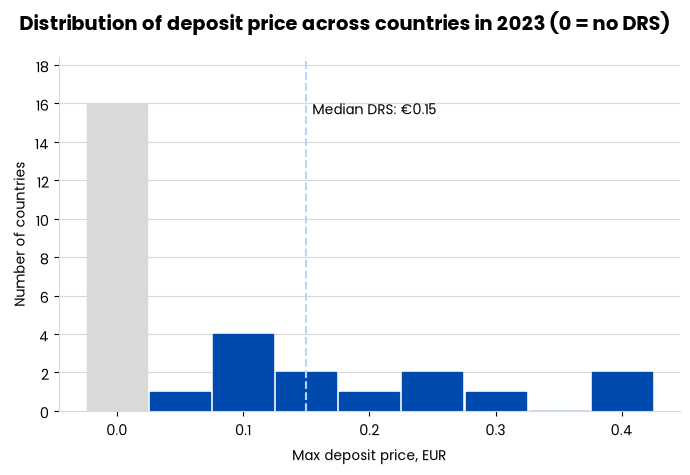

In [12]:
# Univariate analysis: distribution of the max deposit (price) per year
# x = deposit price (EUR), y = number of countries. Countries without DRS count as price 0.
import logging
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np

# --- Poppins: load the .ttf files from the fonts/ folder next to the notebook ---
for f in Path("fonts").glob("Poppins-*.ttf"):
    fm.fontManager.addfont(str(f))
plt.rcParams["font.family"] = "Poppins"
# optional: hide leftover findfont warnings if a weight is missing
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

LIGHT_BLUE, BLUE, GREY, BLACK = "#b5d5ff", "#004aad", "#d9d9d9", "#000000"

#YEARS = [2019, 2020, 2021, 2022, 2023]   # deposit values are only known from ~2018 (full coverage from 2019)
YEARS = [2023]
STEP = 0.05                              # bin width in EUR; bins are centred on 0, 0.05, 0.10, ...

edges = np.arange(-STEP / 2, panel["deposit_max_eur"].max() + STEP, STEP)
centers = (edges[:-1] + edges[1:]) / 2

fig, axes = plt.subplots(1, len(YEARS), figsize=(max(7, 3.4 * len(YEARS)), 4.8),
                         sharey=True, sharex=True, squeeze=False)
axes = axes.ravel()      # always a 1-D array, even for a single year

for ax, yr in zip(axes, YEARS):
    vals = panel.loc[panel["year"] == yr, "deposit_max_eur"].dropna()   # 0 = no DRS
    counts, _ = np.histogram(vals, bins=edges)
    ax.bar(centers, counts, width=STEP * 0.95,
           color=[GREY if c == 0 else BLUE for c in centers],
           edgecolor=[GREY if c == 0 else BLUE for c in centers])
    ax.set_ylim(0, counts.max() * 1.15)          # headroom; must come before the text below
    drs = vals[vals > 0]
    if len(drs):
        ax.axvline(drs.median(), color=LIGHT_BLUE, lw=1.5, ls="--")
        ax.text(drs.median() + 0.005, ax.get_ylim()[1] * 0.88,
                f"Median DRS: €{drs.median():.2f}",
                color=BLACK, fontsize=10, va="top", ha="left")
    #ax.set_title(f"{yr}  (n = {len(vals)})", color=BLUE, fontweight="semibold")
    ax.set_xlabel("Max deposit price, EUR")
    ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(axis="y", color=GREY, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(GREY)

axes[0].set_ylabel("Number of countries")
fig.suptitle("Distribution of deposit price across countries in 2023 (0 = no DRS)",
             color=BLACK, fontsize=14, fontweight="semibold")
plt.tight_layout()
plt.show()

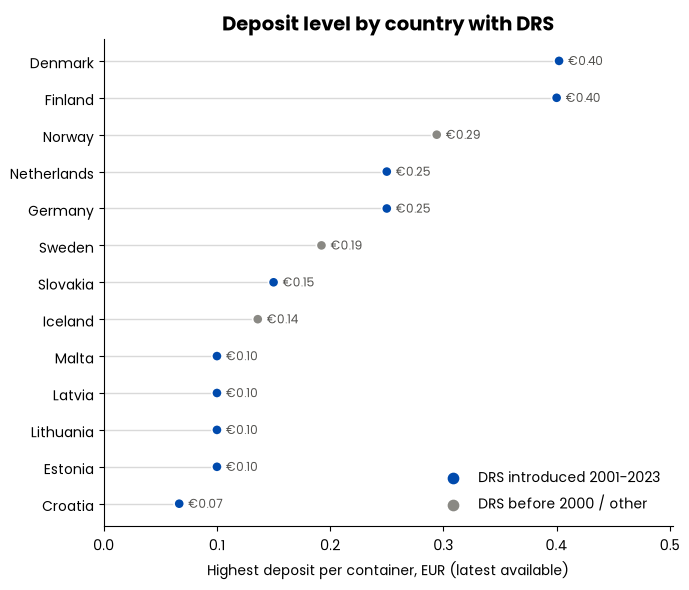

In [5]:
# Panel B on its own: highest deposit per container, by country (latest snapshot available)
import logging
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import pandas as pd

# --- Poppins from the fonts/ folder ---
for f in Path("fonts").glob("Poppins-*.ttf"):
    fm.fontManager.addfont(str(f))
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams.update({"font.family": "Poppins", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA_DIR = Path("data")
panel = pd.read_csv(DATA_DIR / "drs_recycling_panel_plastic.csv")
snap = pd.read_csv(DATA_DIR / "drs_deposit_snapshots_plastic.csv")

ADOPT, BEFORE = "2_drs_introduced_in_window", "1_drs_before_window"
BLUE, GREY, GRID, INK2 = "#004aad", "#8a8984", "#d9d9d9", "#52514e"
# (original notebook colours: BLUE "#2a78d6", GRID "#e4e3df"; swap in if you prefer)

# Latest deposit snapshot per country (only countries with a deposit > 0)
deposit = (snap.dropna(subset=["deposit_max_eur"]).query("deposit_max_eur > 0")
               .sort_values("snapshot_year").groupby("geo")["deposit_max_eur"].last())
dep = (deposit.to_frame("eur")
              .join(panel.drop_duplicates("geo").set_index("geo")[["country", "drs_group"]])
              .sort_values("eur"))
colours = dep["drs_group"].map({ADOPT: BLUE, BEFORE: GREY}).fillna(GREY)

fig, ax = plt.subplots(figsize=(7, 6))
ax.hlines(range(len(dep)), 0, dep["eur"], color=GRID, lw=1)
ax.scatter(dep["eur"], range(len(dep)), color=colours, s=55, zorder=3,
           edgecolor="white", linewidth=1.2)
for i, v in enumerate(dep["eur"]):
    ax.text(v + 0.008, i, f"€{v:.2f}", va="center", fontsize=8.5, color=INK2)

ax.set_yticks(range(len(dep)), dep["country"])
ax.set_xlim(0, dep["eur"].max() * 1.25)
ax.set_xlabel("Highest deposit per container, EUR (latest available)")
ax.set_title("Deposit level by country with DRS", loc="center", fontsize=14, fontweight="semibold")

ax.scatter([], [], color=BLUE, s=55, label="DRS introduced 2001-2023")
ax.scatter([], [], color=GREY, s=55, label="DRS before 2000 / other")
ax.legend(frameon=False, loc="lower right")

fig.tight_layout()
fig.savefig("deposit_level_by_country.png", dpi=200, bbox_inches="tight")
plt.show()